# 01. Nucleotide Transformer 임베딩 + 프로모터 probe (6-mer baseline과 비교)

**등급**: 🟢 Mac 로컬 (MPS/CPU) · **예상 시간**: 8~15분 · **다운로드**: NT v1 500M(사람 참조 게놈) 약 1.9 GB (**라이선스 CC BY-NC-SA 4.0 — 비상업 연구·학습용**), NT 다운스트림 과제 데이터 약 6 MB

**질문**: 사람 참조 게놈으로 사전학습한 DNA 언어모델의 임베딩에 **선형 probe**를 얹으면, **6-mer 빈도만 쓰는 단순 baseline**보다 프로모터를 잘 구분하는가? 층에 따라 다른가? 서열을 몇 염기 밀거나 뒤집으면 흔들리는가?

**설계**
- 과제: 300 bp 서열이 프로모터인지 분류한다. NT 논문의 다운스트림 과제 중 `promoter_tata`(TATA 박스 포함)와 `promoter_no_tata`를 쓴다.
- 특징: (B) 6-mer 빈도 4,096차원, (E) NT 평균 임베딩(층 6/12/18/24)
- 분류기: 표준화 + 로지스틱 회귀, 정규화 강도 C는 **train 안에서 염색체 단위 그룹 CV**로 선택 (보고 지표와 같은 AUROC 기준)
- 평가: 주어진 test split (아래에서 **염색체 분리**를 직접 확인)

> 모듈 02에서 배운 대로 probe는 **표현의 선형 분리성**을 본다. baseline과 같은 split·같은 튜닝 절차를 쓴다.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
if ROOT is not None:
    os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "hf"))     # 원하면 지워 기본 HF 캐시를 쓴다

import torch
from huggingface_hub import snapshot_download
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoTokenizer, EsmModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
print("device:", DEVICE, "| HF_HOME:", os.environ.get("HF_HOME", "(default)"))

W1110 11:47:01.557000 23420 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | HF_HOME: <repo>/.cache/hf


## 1. 데이터와 split 점검
출처: Hugging Face `InstaDeepAI/nucleotide_transformer_downstream_tasks_revised` (NT 논문의 18개 다운스트림 과제 중 2개).
높은 점수가 **누출**에서 나오지 않는지 먼저 확인한다. 확인할 것은 train/test의 염색체 분리, 이름(좌표) 중복, 라벨 균형이다.

In [2]:
NT_TASKS = "InstaDeepAI/nucleotide_transformer_downstream_tasks_revised"
root = snapshot_download(NT_TASKS, repo_type="dataset", allow_patterns=["promoter_tata/*.parquet", "promoter_no_tata/*.parquet"])
tasks = {t: {sp: pd.read_parquet(f"{root}/{t}/{sp}.parquet") for sp in ["train", "test"]} for t in ["promoter_tata", "promoter_no_tata"]}
for t, d in tasks.items():
    for sp in d:
        d[sp]["chrom"] = d[sp].name.str.split(":").str[0]
    tr, te = d["train"], d["test"]
    print(f"{t:17s} train={len(tr):6d} test={len(te):5d} | 길이 {tr.sequence.str.len().min()}~{tr.sequence.str.len().max()} | "
          f"양성 비율 train {tr.label.mean():.2f} / test {te.label.mean():.2f}")
    print(f"{'':17s} test 염색체: {sorted(te.chrom.unique())} | train에 같은 염색체 있나: {bool(set(tr.chrom) & set(te.chrom))} | 이름 중복: {len(set(tr.name) & set(te.name))}")
    print(f"{'':17s} 'N' 포함 서열: train {int(tr.sequence.str.contains('N').sum())} / test {int(te.sequence.str.contains('N').sum())}")

promoter_tata     train=  5062 test=  212 | 길이 300~300 | 양성 비율 train 0.50 / test 0.50
                  test 염색체: ['chr20', 'chr21'] | train에 같은 염색체 있나: False | 이름 중복: 0
                  'N' 포함 서열: train 0 / test 0
promoter_no_tata  train= 30000 test= 1372 | 길이 300~300 | 양성 비율 train 0.50 / test 0.50
                  test 염색체: ['chr20', 'chr21'] | train에 같은 염색체 있나: False | 이름 중복: 0
                  'N' 포함 서열: train 0 / test 0


**읽는 법**: test는 **chr20·chr21**뿐이고 train은 다른 염색체이므로 염색체 단위 holdout이 되어 있다 (모듈 01 5.2의 DNA 권장 split). 같은 염색체 안의 인접 창이 train·test에 섞이는 누출은 없다.
**사전학습–평가 겹침(별개의 문제)**: NT v1(사람 참조)은 모델 카드에 따르면 **GRCh38 참조 게놈 전체**로 사전학습되었으므로 test 염색체(chr20·chr21)의 서열도 (라벨 없이) 이미 보았다.
probe의 라벨 누출은 아니지만, 6-mer 빈도 baseline은 이런 사전 노출이 없으므로 비교가 완전히 대칭이 아니다 (모듈 01 5.2의 "공통" 행).
다만 test 염색체가 2개뿐이라 염색체 단위 신뢰구간은 만들 수 없다. 아래 신뢰구간은 test 서열을 재표본한 것이며 인접 창의 상관을 무시하므로 **낙관적**일 수 있다.

## 2. 모델과 토크나이저
NT v1은 서열을 **겹치지 않는 6-mer**로 자르고 남는 끝부분은 단일 뉴클레오타이드 토큰으로 둔다 (모듈 01 노트북 01의 비겹침 k-mer).
`transformers`의 기본 `EsmModel` 구조라 **원격 코드 실행이 필요 없다**.

In [3]:
NT = "InstaDeepAI/nucleotide-transformer-500m-human-ref"
tok = AutoTokenizer.from_pretrained(NT)
model = EsmModel.from_pretrained(NT, add_pooling_layer=False).to(DEVICE).eval()
print("params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6), "| layers:", model.config.num_hidden_layers, "| hidden:", model.config.hidden_size)

s = tasks["promoter_tata"]["train"].sequence.iloc[0]
for k in [0, 1]:
    ids = tok(s[k:])["input_ids"]
    print(f"{300 - k} bp → 토큰 {len(ids)}개: {tok.convert_ids_to_tokens(ids)[:3]} ... {tok.convert_ids_to_tokens(ids)[-3:]}")

params (M): 479 | layers: 24 | hidden: 1280
300 bp → 토큰 51개: ['<cls>', 'ATGTGG', 'AACTCA'] ... ['GTGATG', 'TCTAGC', 'TCTGTT']
299 bp → 토큰 55개: ['<cls>', 'TGTGGA', 'ACTCAA'] ... ['G', 'T', 'T']


300 bp는 `<cls>` + 6-mer 50개 = 51토큰이지만, **한 염기만 잘라 내도** 299 bp가 되어 6-mer 49개 + 단일 뉴클레오타이드 5개로 토큰이 모두 달라진다. 이 민감도는 4절에서 직접 잰다.

## 3. 임베딩 추출
서열마다 **평균 임베딩**(`<cls>`·패딩 제외)을 여러 층에서 뽑는다. `hidden_states[0]`은 임베딩 층 출력, `hidden_states[24]`는 마지막 층이다.
중간 층이 마지막 층보다 나은지는 과제마다 다르다†.

In [4]:
LAYERS = [6, 12, 18, 24]
SPECIAL = torch.tensor(tok.all_special_ids, device=DEVICE)


@torch.no_grad()
def embed(seqs, layers=LAYERS, batch=64):
    out = {l: [] for l in layers}
    for s in range(0, len(seqs), batch):
        enc = tok(list(seqs[s:s + batch]), return_tensors="pt", padding=True).to(DEVICE)
        hs = model(**enc, output_hidden_states=True).hidden_states
        m = (enc["attention_mask"].bool() & ~torch.isin(enc["input_ids"], SPECIAL)).float()     # 패딩·<cls> 제외
        for l in layers:
            out[l].append(((hs[l] * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)).float().cpu())
    return {l: torch.cat(v).numpy() for l, v in out.items()}


# 정합성: 단독 입력과 패딩된 배치 입력의 평균 임베딩이 같아야 한다
a = embed([s])[24]
b = embed([s, s[:250]])[24]
print("패딩 유무에 따른 마지막 층 평균 임베딩 최대 차이:", float(np.abs(a[0] - b[0]).max()))

패딩 유무에 따른 마지막 층 평균 임베딩 최대 차이: 1.9073486328125e-06


## 4. 특징 계산과 학습
`promoter_no_tata` train은 30,000개라 임베딩에 시간이 걸린다. **무작위 6,000개**만 쓴다 (`N_TRAIN`). `promoter_tata`는 전부(5,062개) 쓴다.
baseline 특징은 같은 서열의 **겹침 6-mer 빈도**(합 1로 정규화, 4,096차원)다.

In [5]:
import time

N_TRAIN = 6000
BASE = {"A": 0, "C": 1, "G": 2, "T": 3}


def kmer_freq(seqs, k=6):
    """겹침 k-mer 빈도(합=1). 'N'을 포함한 k-mer는 건너뛴다."""
    rows, cols = [], []
    for i, s in enumerate(seqs):
        a = np.array([BASE.get(c, -1) for c in s])
        idx = sum(a[j:len(a) - k + 1 + j] * 4 ** (k - 1 - j) for j in range(k))
        ok = np.all([a[j:len(a) - k + 1 + j] >= 0 for j in range(k)], axis=0)
        cols.append(idx[ok])
        rows.append(np.full(ok.sum(), i))
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    M = sparse.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(seqs), 4 ** k))
    return np.asarray((sparse.diags(1.0 / np.maximum(M.sum(1).A1, 1)) @ M).todense())


data = {}
t0 = time.time()
for t, d in tasks.items():
    tr = d["train"].sample(n=min(N_TRAIN, len(d["train"])), random_state=SEED).reset_index(drop=True)
    te = d["test"].reset_index(drop=True)
    feats = {"6-mer freq": (kmer_freq(tr.sequence), kmer_freq(te.sequence))}
    Etr, Ete = embed(tr.sequence.tolist()), embed(te.sequence.tolist())
    for l in LAYERS:
        feats[f"NT layer {l}"] = (Etr[l], Ete[l])
    data[t] = dict(tr=tr, te=te, feats=feats)
    print(f"{t}: train {len(tr)}, test {len(te)} 완료 ({time.time() - t0:.0f}s 경과)")

promoter_tata: train 5062, test 212 완료 (84s 경과)


promoter_no_tata: train 6000, test 1372 완료 (199s 경과)


In [6]:
def fit_eval(Xtr, ytr, gtr, Xte, yte, n_boot=300, seed=0):
    """C는 train 안에서 염색체 단위 그룹 CV(AUROC 기준)로 고르고, test는 한 번만 본다."""
    splits = list(GroupKFold(n_splits=3).split(Xtr, ytr, gtr))
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    gs = GridSearchCV(pipe, {"logisticregression__C": [1e-4, 1e-3, 1e-2, 1e-1]}, cv=splits, scoring="roc_auc")
    gs.fit(Xtr, ytr)
    p = gs.predict_proba(Xte)[:, 1]
    rs = np.random.RandomState(seed)
    boots = [roc_auc_score(yte[i], p[i]) for i in (rs.randint(0, len(yte), len(yte)) for _ in range(n_boot))]
    return dict(auroc=roc_auc_score(yte, p), lo=np.percentile(boots, 2.5), hi=np.percentile(boots, 97.5),
                mcc=matthews_corrcoef(yte, p > 0.5), cv_auroc=gs.best_score_, C=gs.best_params_["logisticregression__C"], model=gs, p=p)


rows, fitted = [], {}
for t, d in data.items():
    ytr, yte, gtr = d["tr"].label.values, d["te"].label.values, d["tr"].chrom.values
    for fname, (Xtr, Xte) in d["feats"].items():
        r = fit_eval(Xtr, ytr, gtr, Xte, yte)
        fitted[(t, fname)] = r
        rows.append(dict(task=t, feature=fname, cv_auroc=r["cv_auroc"], auroc=r["auroc"], lo=r["lo"], hi=r["hi"], mcc=r["mcc"], C=r["C"]))
res = pd.DataFrame(rows)
print("완료")

완료


## 5. 결과 — test AUROC (괄호: test 서열 재표본 95% 구간), MCC

In [7]:
for t in res.task.unique():
    sub = res[res.task == t].copy()
    sub["AUROC [95% CI]"] = sub.apply(lambda r: f"{r.auroc:.3f} [{r.lo:.3f},{r.hi:.3f}]", axis=1)
    print(f"\n=== {t} (test n={len(data[t]['te'])}) ===")
    sub["C"] = sub["C"].map(lambda c: f"{c:.0e}")                      # 1e-4가 0.000으로 보이지 않게 과학적 표기
    print(sub[["feature", "cv_auroc", "AUROC [95% CI]", "mcc", "C"]].round(3).to_string(index=False))


=== promoter_tata (test n=212) ===
    feature  cv_auroc      AUROC [95% CI]   mcc     C
 6-mer freq     0.891 0.925 [0.892,0.957] 0.673 1e-03
 NT layer 6     0.874 0.895 [0.848,0.928] 0.576 1e-03
NT layer 12     0.908 0.925 [0.889,0.955] 0.662 1e-02
NT layer 18     0.905 0.942 [0.908,0.970] 0.760 1e-03
NT layer 24     0.900 0.946 [0.914,0.972] 0.739 1e-03

=== promoter_no_tata (test n=1372) ===
    feature  cv_auroc      AUROC [95% CI]   mcc     C
 6-mer freq     0.922 0.936 [0.924,0.949] 0.727 1e-04
 NT layer 6     0.922 0.935 [0.923,0.947] 0.720 1e-03
NT layer 12     0.934 0.948 [0.938,0.958] 0.738 1e-03
NT layer 18     0.936 0.946 [0.936,0.956] 0.743 1e-03
NT layer 24     0.933 0.944 [0.934,0.955] 0.737 1e-03


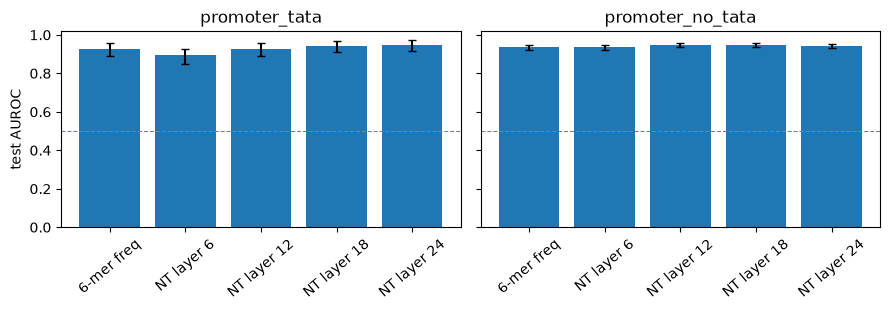

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, t in zip(axes, res.task.unique()):
    sub = res[res.task == t]
    ax.bar(sub.feature, sub.auroc, yerr=[sub.auroc - sub.lo, sub.hi - sub.auroc], capsize=3)
    ax.axhline(0.5, color="gray", ls="--", lw=0.8)
    ax.set_title(t)
    ax.tick_params(axis="x", rotation=40)
axes[0].set_ylabel("test AUROC")
plt.tight_layout()
plt.show()

### 짝지은 비교: NT(train CV로 고른 층) − 6-mer baseline
두 방법의 개별 신뢰구간이 겹친다는 사실만으로 차이의 유무를 판단할 수 없다. **같은 test 서열**에서 AUROC 차이를 직접 재표본한다 (인접 창의 상관을 무시하므로 여전히 낙관적일 수 있다).

In [9]:
def paired_delta(t, f_a, f_b, n_boot=1000, seed=0):
    pa, pb = fitted[(t, f_a)]["p"], fitted[(t, f_b)]["p"]
    yt = data[t]["te"].label.values
    rs, ds = np.random.RandomState(seed), []
    for _ in range(n_boot):
        i = rs.randint(0, len(yt), len(yt))
        if yt[i].min() != yt[i].max():
            ds.append(roc_auc_score(yt[i], pa[i]) - roc_auc_score(yt[i], pb[i]))
    return roc_auc_score(yt, pa) - roc_auc_score(yt, pb), *np.percentile(ds, [2.5, 97.5])


for t in data:
    best = max((f for f in data[t]["feats"] if f.startswith("NT")), key=lambda f: fitted[(t, f)]["cv_auroc"])
    d_, lo_, hi_ = paired_delta(t, best, "6-mer freq")
    print(f"{t:17s} {best} − 6-mer: ΔAUROC = {d_:+.3f} [{lo_:+.3f}, {hi_:+.3f}]  (층은 train CV로만 선택)")

promoter_tata     NT layer 12 − 6-mer: ΔAUROC = +0.001 [-0.030, +0.029]  (층은 train CV로만 선택)


promoter_no_tata  NT layer 18 − 6-mer: ΔAUROC = +0.010 [+0.003, +0.017]  (층은 train CV로만 선택)


## 6. 프레임 이동·reverse complement에 대한 민감도
**train에서만 고른** 최고 층(CV AUROC 기준)의 probe를 `promoter_no_tata`에 대해 고정하고, test 서열을 (a) 앞에서 1~5 nt 잘라 내거나 (b) reverse complement로 바꿔 다시 평가한다.
앞만 잘라 내면 길이가 6의 배수가 아니게 되어 서열 **끝**이 단일 염기 토큰 최대 5개로 쪼개진다(2절의 299 bp → 55토큰). 그래서 프레임 이동 효과와 "끝의 토큰 종류 변화·서열 손실"이 섞인다.
이를 분리하려고 **294 bp(=49×6)로 길이를 맞춘** 행을 함께 보고한다 (294 bp, 이동 0은 길이만 줄인 대조).
probe는 **원래 서열**로 학습했다. 6-mer 빈도 baseline도 같은 변형을 적용한다. 프로모터는 방향이 있으므로 reverse complement는 라벨이 같다고 가정할 수 없다는 점에 주의한다(변화가 클 수 있다).

In [10]:
t = "promoter_no_tata"
d = data[t]
best_layer = max((f for f in d["feats"] if f.startswith("NT")), key=lambda f: fitted[(t, f)]["cv_auroc"])
print("train CV로 고른 NT 특징:", best_layer, "| CV AUROC", round(fitted[(t, best_layer)]["cv_auroc"], 3))
l_best = int(best_layer.split()[-1])
yte = d["te"].label.values
comp = str.maketrans("ACGTN", "TGCAN")


def eval_variant(transform):
    seqs = [transform(s) for s in d["te"].sequence]
    e = embed(seqs, layers=[l_best])[l_best]
    k = kmer_freq(seqs)
    return (roc_auc_score(yte, fitted[(t, best_layer)]["model"].predict_proba(e)[:, 1]),
            roc_auc_score(yte, fitted[(t, "6-mer freq")]["model"].predict_proba(k)[:, 1]))


rob = []
for shift in [0, 1, 2, 3, 4, 5]:
    a_nt, a_kmer = eval_variant(lambda s, k=shift: s[k:])
    rob.append(dict(변형=f"앞 {shift} nt 제거 (끝에 단일 염기 토큰 생김)", NT=a_nt, kmer=a_kmer))
for shift in [0, 1, 2, 3, 4, 5]:
    a_nt, a_kmer = eval_variant(lambda s, k=shift: s[k:k + 294])       # 294 = 49 × 6: 끝의 단일 염기 토큰 없이 순수 프레임 이동만
    rob.append(dict(변형=f"앞 {shift} nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)", NT=a_nt, kmer=a_kmer))
a_nt, a_kmer = eval_variant(lambda s: s.translate(comp)[::-1])
rob.append(dict(변형="reverse complement", NT=a_nt, kmer=a_kmer))
rob = pd.DataFrame(rob).set_index("변형")
rob.columns = [f"NT {best_layer.split()[-1]}층 probe", "6-mer baseline"]
print(rob.round(3).to_string())

train CV로 고른 NT 특징: NT layer 18 | CV AUROC 0.936


                                    NT 18층 probe  6-mer baseline
변형                                                              
앞 0 nt 제거 (끝에 단일 염기 토큰 생김)                 0.946           0.936
앞 1 nt 제거 (끝에 단일 염기 토큰 생김)                 0.940           0.936
앞 2 nt 제거 (끝에 단일 염기 토큰 생김)                 0.939           0.936
앞 3 nt 제거 (끝에 단일 염기 토큰 생김)                 0.938           0.936
앞 4 nt 제거 (끝에 단일 염기 토큰 생김)                 0.940           0.936
앞 5 nt 제거 (끝에 단일 염기 토큰 생김)                 0.941           0.936
앞 0 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.946           0.937
앞 1 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.942           0.936
앞 2 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.942           0.936
앞 3 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.940           0.936
앞 4 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.941           0.936
앞 5 nt 제거 + 294 bp로 맞춤 (순수 프레임 이동)         0.941           0.936
reverse complement                         0.930           0.931


## 7. 해석 가이드와 한계
아래는 이 실행(seed=0, MPS)에서 읽은 내용이다. **표를 직접 확인한다.**

- **이 과제는 6-mer 빈도만으로도 꽤 풀린다.** baseline AUROC가 `promoter_tata` 0.925, `promoter_no_tata` 0.936이다. 쉬운 과제에서는 임베딩이 더할 여지가 작다.
- **NT 임베딩의 이득은 작다.** **train CV로 고른 층**을 짝지은 재표본으로 6-mer와 비교하면 `promoter_no_tata`(test 1,372개)는 NT 18층 ΔAUROC = +0.010 [+0.003, +0.017]로 작지만 0을 포함하지 않는다(재표본이 인접 창의 상관을 무시해 낙관적일 수 있음).
  `promoter_tata`(test 212개)는 12층 +0.001 [−0.030, +0.029]로 **차이가 없다**. 이 test에서 18·24층(0.942, 0.946)이 더 높게 나왔지만 **test를 보고 층을 고르면 안 된다.** 층 선택은 train CV로만 한다.
- **층에 따라 다르다.** 6층은 baseline과 비슷하거나 낮고(0.895, 0.935) 12층 이상에서 오른다. 마지막 층이 항상 최선은 아니다(`promoter_no_tata`는 12층 0.948 ≥ 24층 0.944, 구간 안의 차이).
- **프레임 이동에 대한 probe의 민감도는 토큰 변화보다 훨씬 작았다.** 앞 1~5 nt를 자르면 토큰이 모두 바뀌지만(2절) 순수 프레임 이동(294 bp로 길이를 맞춘 행)에서 probe AUROC는 0.946에서 0.940~0.942로, 0.006 이내만 떨어졌다. 끝의 단일 염기 토큰이 생기는 행(0.938~0.941)과의 차이는 0.003 이내라 **끝 토큰 효과는 작았다**. 6-mer baseline은 0.936~0.937로 변하지 않았다. 평균 풀링이 토큰 수준 변화를 희석했을 수 있다(가설).
- **reverse complement도 크게 영향을 주지 않았다.** NT 0.930, baseline 0.931(원래 0.946, 0.936). 프로모터 방향 정보가 이 분류에서 크게 필요하지 않거나 6-mer 조성이 비교적 대칭이라는 가설이 있다. 직접 확인하지는 않았다.
- **사전학습 노출**: NT는 test 염색체를 포함한 GRCh38 전체로 사전학습되어 6-mer baseline과 비교가 완전히 대칭이 아니다(1절). 신뢰구간은 test **서열 재표본**이라 인접 창의 상관을 무시해 낙관적일 수 있다.

## 8. 한계와 과제
- 과제 2개, 300 bp 창, test 염색체 2개다. 일반화된 결론으로 쓰면 안 된다.
- `promoter_no_tata`는 train 30,000개 중 **6,000개만** 무작위로 써서 학습했다. 고차원 특징(6-mer 4,096차원 vs NT 1,280차원)의 상대 성능은 학습 샘플 수에 따라 달라질 수 있어 전체 데이터로는 결과가 다를 수 있다 (과제 1).
- NT v1 500M(사람 참조)만 썼다. 다종 학습·더 큰 모델·미세조정은 결과가 다를 수 있다.
- 이 노트북의 probe는 **지도학습**(프로모터 라벨 사용)이다. 라벨 없는 zero-shot 변이 점수는 다음 노트북에서 다룬다.
- 라이선스: NT v1 가중치는 CC BY-NC-SA 4.0이므로 **비상업 목적**으로만 사용한다.
- 과제: [../exercises.md](../exercises.md) 과제 1.